## 1. Setup and Hugging Face Login

In [1]:
!pip install ijson -q
import os
import gc
import json
import math
import time
import random
import zipfile

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler
import matplotlib.pyplot as plt

from huggingface_hub import login, hf_hub_download, HfApi
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.9/149.9 kB 3.6 MB/s eta 0:00:00a 0:00:01


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. GPU Check

In [2]:
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")
    print(f"  Memory: {torch.cuda.get_device_properties(i).total_memory / 1e9:.1f} GB")

CUDA available: True
GPU count: 2
GPU 0: Tesla T4
  Memory: 15.6 GB
GPU 1: Tesla T4
  Memory: 15.6 GB


## 3. Configuration

In [3]:
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
HF_MODEL_REPO = "D-240357/legal-gpt2-decoder"

TRAIN_FILES = [
    "Phase_1_Pretraining/Train/train_acts.json",
    "Phase_1_Pretraining/Train/train_high_courts.json",
    "Phase_1_Pretraining/Train/train_supreme_court.json",
    "Phase_1_Pretraining/Train/train_tribunals.json",
]
TEST_FILE = "Phase_1_Pretraining/Test/test.json"
TRAIN_TOKENS = 600_000_000

# Resume: step to resume from (loaded from HF commit history). None = latest checkpoint on HF.
RESUME_STEP = 18000
PUSH_EVERY = 500   # steps between checkpoint pushes to HF


VAL_RATIO = 0.10
BLOCK_SIZE = 2048
SEED = 42

VOCAB_SIZE = 32000
N_EMBD = 768
N_LAYER = 12
N_HEAD = 12
D_FF = 3072
DROPOUT = 0.1
CONTEXT_LENGTH = 2048

BATCH_SIZE = 4
GRAD_ACCUM = 4
LEARNING_RATE = 3e-4
WARMUP_STEPS = 500
WEIGHT_DECAY = 0.1
MAX_GRAD_NORM = 1.0

TARGET_WORDS = 128
MAX_NEW_TOKENS = 384
GEN_TEMPERATURE = 0.7
GEN_TOP_P = 0.92
GEN_TOP_K = 50

TOKENIZER_TRAIN_DOCS = 50000

OUTPUT_DIR = "/kaggle/working/arch1_gpt2"
MODEL_DIR = os.path.join(OUTPUT_DIR, "model")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")
TOKENIZER_PATH = os.path.join(MODEL_DIR, "tokenizer.json")
os.makedirs(MODEL_DIR, exist_ok=True)

random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Configuration loaded.")

Configuration loaded.


## 4. Download Training Data

In [4]:
train_file_paths = []
for fname in TRAIN_FILES:
    path = hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=fname,
        repo_type="dataset",
        token=HF_TOKEN
    )
    train_file_paths.append(path)
    print(f"Downloaded: {fname}")

print(f"Total training files: {len(train_file_paths)}")

Phase_1_Pretraining/Train/train_acts.jso(…): reconstructing file:   0%|          |  0.00B /  729MB            

Phase_1_Pretraining/Train/train_acts.jso(…): downloading bytes:           |  0.00B            

Downloaded: Phase_1_Pretraining/Train/train_acts.json


Phase_1_Pretraining/Train/train_high_cou(…): reconstructing file:   0%|          |  0.00B / 10.7GB            

Phase_1_Pretraining/Train/train_high_cou(…): downloading bytes:           |  0.00B            

Downloaded: Phase_1_Pretraining/Train/train_high_courts.json


... (2 outputs left out)

Downloaded: Phase_1_Pretraining/Train/train_supreme_court.json


Phase_1_Pretraining/Train/train_tribunal(…): reconstructing file:   0%|          |  0.00B / 6.48GB            

Phase_1_Pretraining/Train/train_tribunal(…): downloading bytes:           |  0.00B            

Downloaded: Phase_1_Pretraining/Train/train_tribunals.json
Total training files: 4


## 5. Define Custom Tokenizer

In [5]:
import re
import json
import array
from collections import Counter

class CustomTokenizer:
    def __init__(self, vocab_size=32000):
        self.vocab_size = vocab_size
        self.special_tokens = ["<pad>", "<unk>", "<bos>", "<eos>"]
        self.word2id = {w: i for i, w in enumerate(self.special_tokens)}
        self.id2word = {i: w for i, w in enumerate(self.special_tokens)}
        self.pad_id = 0
        self.unk_id = 1
        self.bos_id = 2
        self.eos_id = 3
        self.counter = Counter()
        
    def _tokenize_text(self, text):
        return re.findall(r"\w+|[^\w\s]", text, re.UNICODE)
        
    def train_single(self, text):
        self.counter.update(self._tokenize_text(text.lower()))
        
    def finalize_training(self):
        most_common = self.counter.most_common(self.vocab_size - len(self.special_tokens))
        for word, _ in most_common:
            idx = len(self.word2id)
            self.word2id[word] = idx
            self.id2word[idx] = word
        self.counter = None
            
    def encode(self, text, add_special_tokens=False):
        tokens = self._tokenize_text(text.lower())
        ids = [self.word2id.get(tok, self.unk_id) for tok in tokens]
        if add_special_tokens:
            ids = [self.bos_id] + ids + [self.eos_id]
        return ids
        
    def decode(self, ids, skip_special_tokens=True):
        words = []
        for i in ids:
            if skip_special_tokens and i < len(self.special_tokens):
                continue
            words.append(self.id2word.get(i, "<unk>"))
        out = " ".join(words)
        out = re.sub(r"\s+([.,!?;\)])", r"\1", out)
        out = re.sub(r"(\()\s+", r"\1", out)
        return out
        
    def save(self, path):
        with open(path, "w", encoding="utf-8") as f:
            json.dump({"word2id": self.word2id, "id2word": {str(k): v for k,v in self.id2word.items()}}, f, ensure_ascii=False)
            
    def load(self, path):
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
            self.word2id = data["word2id"]
            self.id2word = {int(k): v for k, v in data["id2word"].items()}
            self.vocab_size = len(self.word2id)

print("CustomTokenizer defined.")

CustomTokenizer defined.


## 5.5 Train Custom Tokenizer

In [6]:
TOKENIZER_PATH = os.path.join(MODEL_DIR, "custom_tokenizer.json")
tokenizer = CustomTokenizer(vocab_size=32000)
_tok_loaded = False
try:
    hf_hub_download(HF_MODEL_REPO, "custom_tokenizer.json", local_dir=MODEL_DIR, token=HF_TOKEN)
    tokenizer.load(TOKENIZER_PATH)
    _tok_loaded = True
    print("Loaded tokenizer from HF (guarantees same vocab as the checkpoint).")
except Exception as e:
    print(f"No tokenizer on HF ({type(e).__name__}); training one.")

if not _tok_loaded:
    print("Streaming texts to train custom tokenizer (Memory efficient)...")
    tokenizer = CustomTokenizer(vocab_size=32000)
    docs_processed = 0

    for fp in train_file_paths:
        print(f"  Reading {os.path.basename(fp)}...")
        chunk_size = 1024 * 1024 * 50  # 50MB
        decoder = json.JSONDecoder()
    
        with open(fp, "r", encoding="utf-8") as f:
            buffer = f.read(chunk_size)
            idx = 0
        
            while idx < len(buffer) and buffer[idx] in ' \t\n\r': idx += 1
            if idx < len(buffer) and buffer[idx] == '[': idx += 1
            
            while True:
                while idx < len(buffer) and buffer[idx] in ' \t\n\r,': idx += 1
                
                if idx >= len(buffer):
                    next_chunk = f.read(chunk_size)
                    if not next_chunk: break
                    buffer = next_chunk
                    idx = 0
                    continue
                
                if buffer[idx] == ']': break
                
                try:
                    r, end_idx = decoder.raw_decode(buffer, idx)
                    tokenizer.train_single(r["text"])
                    docs_processed += 1
                    if docs_processed >= 15000:
                        break
                    idx = end_idx
                except json.JSONDecodeError:
                    remainder = buffer[idx:]
                    next_chunk = f.read(chunk_size)
                    if not next_chunk: break
                    buffer = remainder + next_chunk
                    idx = 0
                
        gc.collect()
        if docs_processed >= 15000:
            break

    print(f"Finalizing vocabulary on {docs_processed} documents...")
    tokenizer.finalize_training()
    tokenizer.save(TOKENIZER_PATH)

VOCAB_SIZE = len(tokenizer.word2id)
PAD_ID = tokenizer.pad_id
EOS_ID = tokenizer.eos_id

print(f"Custom vocabulary size: {VOCAB_SIZE}")
print(f"PAD={PAD_ID}, EOS={EOS_ID}")


custom_tokenizer.json:   0%|          | 0.00/1.20M [00:00<?, ?B/s]

Loaded tokenizer from HF (guarantees same vocab as the checkpoint).
Custom vocabulary size: 32000
PAD=0, EOS=3


## 6. Tokenize and Create Splits

In [7]:
import ijson
from torch.utils.data import IterableDataset, DataLoader

class StreamingLegalDataset(IterableDataset):
    def __init__(self, file_paths, tokenizer, max_tokens, block_size, skip_blocks=0):
        self.file_paths = file_paths
        self.tokenizer = tokenizer
        self.max_tokens = max_tokens
        self.block_size = block_size
        self.skip_blocks = skip_blocks  # fast-forward for resume (no tensors built)

    def _stream_files(self):
        yielded = 0
        skipped = 0
        buf = []
        for fp in self.file_paths:
            with open(fp, 'rb') as f:
                for rec in ijson.items(f, 'item'):
                    text = rec.get('text', '')
                    if len(text) < 100:
                        continue
                    # CustomTokenizer encode
                    ids = self.tokenizer.encode(text)
                    buf.extend(ids)
                    while len(buf) >= self.block_size + 1:
                        if skipped < self.skip_blocks:
                            buf = buf[self.block_size:]
                            skipped += 1
                            yielded += self.block_size
                            if yielded >= self.max_tokens:
                                return
                            continue
                        chunk = buf[:self.block_size + 1]
                        buf = buf[self.block_size:]
                        yield (
                            torch.tensor(chunk[:-1], dtype=torch.long),
                            torch.tensor(chunk[1:], dtype=torch.long)
                        )
                        yielded += self.block_size
                        if yielded >= self.max_tokens:
                            return

    def __iter__(self):
        return self._stream_files()

print("Streaming dataset class defined.")


Streaming dataset class defined.


In [8]:
train_dataset = StreamingLegalDataset(
    file_paths=train_file_paths,
    tokenizer=tokenizer,
    max_tokens=TRAIN_TOKENS,
    block_size=BLOCK_SIZE
)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, num_workers=0, pin_memory=True)

print(f"Train dataloader initialized for {TRAIN_TOKENS} tokens.")


Train dataloader initialized for 600000000 tokens.


## 7. Create Token Blocks

In [9]:
# Token blocks are now handled inside StreamingLegalDataset\n

## 8. Build Datasets and DataLoader

In [10]:
# Datasets and loaders are already configured.\n

## 9. Define Model

In [11]:
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_head, dropout, max_len):
        super().__init__()
        self.n_head = n_head
        self.head_dim = d_model // n_head
        self.W_qkv = nn.Linear(d_model, 3 * d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.resid_drop = nn.Dropout(dropout)
        self.dropout_p = dropout

    def forward(self, x):
        B, T, D = x.shape
        qkv = self.W_qkv(x).reshape(B, T, 3, self.n_head, self.head_dim)
        qkv = qkv.permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        out = F.scaled_dot_product_attention(q, k, v, is_causal=True, dropout_p=self.dropout_p if self.training else 0.0)
        out = out.permute(0, 2, 1, 3).reshape(B, T, D)
        return self.resid_drop(self.W_o(out))


class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout):
        super().__init__()
        self.up = nn.Linear(d_model, d_ff)
        self.down = nn.Linear(d_ff, d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.drop(self.down(F.gelu(self.up(x))))


class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_head, d_ff, dropout, max_len):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = CausalSelfAttention(d_model, n_head, dropout, max_len)
        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = FeedForward(d_model, d_ff, dropout)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.ffn(self.ln2(x))
        return x


class GPT2LM(nn.Module):
    def __init__(self, vocab_size, d_model, n_head, n_layer, d_ff, dropout, max_len):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(max_len, d_model)
        self.emb_drop = nn.Dropout(dropout)

        self.layers = nn.ModuleList([
            TransformerBlock(d_model, n_head, d_ff, dropout, max_len)
            for _ in range(n_layer)
        ])

        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        self.head.weight = self.token_emb.weight

        self._init_weights()

    def _init_weights(self):
        for module in self.modules():
            if isinstance(module, nn.Linear):
                nn.init.normal_(module.weight, std=0.02)
                if module.bias is not None:
                    nn.init.zeros_(module.bias)
            elif isinstance(module, nn.Embedding):
                nn.init.normal_(module.weight, std=0.02)

    def forward(self, x):
        B, T = x.shape
        positions = torch.arange(T, device=x.device).unsqueeze(0)
        h = self.emb_drop(self.token_emb(x) + self.pos_emb(positions))
        for layer in self.layers:
            h = layer(h)
        h = self.ln_f(h)
        return self.head(h)


model = GPT2LM(
    vocab_size=VOCAB_SIZE,
    d_model=N_EMBD,
    n_head=N_HEAD,
    n_layer=N_LAYER,
    d_ff=D_FF,
    dropout=DROPOUT,
    max_len=CONTEXT_LENGTH
).to(device)

model = torch.compile(model)

param_count = sum(p.numel() for p in model.parameters())
assert 50_000_000 <= param_count <= 300_000_000, f"Param count {param_count} out of range"
print(f"GPT-2 Decoder parameters: {param_count / 1e6:.2f}M")


GPT-2 Decoder parameters: 111.20M


In [12]:
import shutil
from huggingface_hub import hf_hub_download, HfApi

api = HfApi()
api.create_repo(HF_MODEL_REPO, token=HF_TOKEN, exist_ok=True)   # make sure pushes can't 404

checkpoint_path = os.path.join(MODEL_DIR, "training_state.pt")

def _ckpt_step(p):
    c = torch.load(p, map_location="cpu", mmap=True)
    return c["global_step"]

print("Checking for existing checkpoint on Hugging Face...")
try:
    if RESUME_STEP is None:
        hf_hub_download(HF_MODEL_REPO, "training_state.pt", local_dir=MODEL_DIR, token=HF_TOKEN)
        print("Downloaded latest checkpoint; training will resume.")
    else:
        found = False
        # newest -> oldest; each push was its own commit
        for commit in api.list_repo_commits(HF_MODEL_REPO, token=HF_TOKEN):
            try:
                p = hf_hub_download(HF_MODEL_REPO, "training_state.pt", revision=commit.commit_id, token=HF_TOKEN)
            except Exception:
                continue
            st = _ckpt_step(p)
            print(f"  commit {commit.commit_id[:8]} -> step {st}")
            if st == RESUME_STEP:
                shutil.copy(p, checkpoint_path)
                found = True
                break
            if st < RESUME_STEP:
                break
        if not found:
            raise RuntimeError(f"No commit with global_step == {RESUME_STEP} found")
        print(f"Checkpoint for step {RESUME_STEP} ready; training will resume.")
except Exception as e:
    if RESUME_STEP is not None:
        raise   # do NOT silently start from scratch when a resume was requested
    print("No checkpoint found on HF Hub. Starting from scratch.", e)


Checking for existing checkpoint on Hugging Face...


training_state.pt: reconstructing file:   0%|          |  0.00B / 1.33GB            

training_state.pt: downloading bytes:           |  0.00B            

  commit ceed8e2a -> step 18300
  commit 187946b3 -> step 18300


training_state.pt: reconstructing file:   0%|          |  0.00B / 1.33GB            

training_state.pt: downloading bytes:           |  0.00B            

... (3 outputs left out)

  commit fe21c0b2 -> step 18100


training_state.pt: reconstructing file:   0%|          |  0.00B / 1.33GB            

training_state.pt: downloading bytes:           |  0.00B            

  commit 69e2aa17 -> step 18000
Checkpoint for step 18000 ready; training will resume.


## 10. Training Loop

In [13]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, betas=(0.9, 0.98), weight_decay=WEIGHT_DECAY)

total_steps = TRAIN_TOKENS // (BATCH_SIZE * BLOCK_SIZE * GRAD_ACCUM)

def lr_lambda(step):
    if step < WARMUP_STEPS:
        return step / max(1, WARMUP_STEPS)
    progress = (step - WARMUP_STEPS) / max(1, total_steps - WARMUP_STEPS)
    return 0.5 * (1.0 + math.cos(math.pi * progress))

scaler = torch.amp.GradScaler('cuda')

global_step = 0
tokens_processed = 0
if os.path.exists(checkpoint_path):
    ckpt = torch.load(checkpoint_path, map_location=device)
    ckpt_model = ckpt["model"]
    if any(k.startswith("_orig_mod.") for k in model.state_dict().keys()) and not any(k.startswith("_orig_mod.") for k in ckpt_model.keys()):
        ckpt_model = {f"_orig_mod.{k}": v for k, v in ckpt_model.items()}
    model.load_state_dict(ckpt_model)
    optimizer.load_state_dict(ckpt["optimizer"])
    if "scaler" in ckpt:
        scaler.load_state_dict(ckpt["scaler"])
    global_step = ckpt["global_step"]
    tokens_processed = ckpt["tokens_processed"]
    del ckpt, ckpt_model
    gc.collect()
    print(f"Resumed from checkpoint at step {global_step} ({tokens_processed/1e6:.1f}M tokens)")

# Rebuild scheduler from global_step (do NOT trust a saved scheduler state: it caused the LR bug)
for g in optimizer.param_groups:
    g["initial_lr"] = LEARNING_RATE
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda, last_epoch=global_step - 1)
exp_lr = LEARNING_RATE * lr_lambda(global_step)
assert abs(scheduler.get_last_lr()[0] - exp_lr) < 1e-12, "scheduler out of sync with global_step"
print(f"Total steps: {total_steps} | resuming at {global_step} | remaining: {max(0, total_steps - global_step)} | LR now: {exp_lr:.2e}")

train_log = {"steps": [], "losses": []}
val_log = {"steps": [], "losses": []}

start_time = time.time()
start_tokens = tokens_processed

model.train()
running_loss = 0.0
batch_count = 0
optimizer.zero_grad()

print(f"Starting streaming training for {TRAIN_TOKENS:,} tokens...")

train_dataset.skip_blocks = global_step * GRAD_ACCUM * BATCH_SIZE
if train_dataset.skip_blocks > 0:
    print(f"Fast-forwarding dataset past {train_dataset.skip_blocks} blocks (tokenizing only, no training)...")
t0 = time.time()
train_iter = iter(train_loader)
first = True

micro_since_log = 0
for x, y in train_iter:
    if first:
        print(f"Fast-forward done in {(time.time()-t0)/60:.1f} min.")
        first = False
        start_time = time.time()
    if tokens_processed >= TRAIN_TOKENS:
        break

    x = x.to(device, non_blocking=True)
    y = y.to(device, non_blocking=True)

    with torch.amp.autocast('cuda'):
        logits = model(x)
        loss = F.cross_entropy(logits.reshape(-1, VOCAB_SIZE), y.reshape(-1))
        loss = loss / GRAD_ACCUM

    scaler.scale(loss).backward()
    running_loss += loss.item() * GRAD_ACCUM
    batch_count += 1
    micro_since_log += 1

    if batch_count % GRAD_ACCUM == 0:
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        optimizer.zero_grad()
        global_step += 1
        tokens_processed += BATCH_SIZE * BLOCK_SIZE * GRAD_ACCUM

        is_last = tokens_processed >= TRAIN_TOKENS
        if global_step % 100 == 0 or is_last:
            avg = running_loss / max(1, micro_since_log)   # mean per-micro-batch loss
            train_log["steps"].append(global_step)
            train_log["losses"].append(avg)
            lr_now = scheduler.get_last_lr()[0]
            elapsed = time.time() - start_time
            tok_s = (tokens_processed - start_tokens) / max(1, elapsed)
            print(f"Step {global_step:5d} | Loss: {avg:.4f} | LR: {lr_now:.2e} | Tok: {tokens_processed/1e6:.1f}M | Speed: {tok_s/1000:.1f}K tok/s")
            running_loss = 0.0
            micro_since_log = 0

        if global_step % PUSH_EVERY == 0 or is_last:
            raw_mod = model.module if hasattr(model, "module") else model
            torch.save({
                "model": {k.replace("_orig_mod.", ""): v for k, v in raw_mod.state_dict().items()},
                "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(),
                "scaler": scaler.state_dict(),
                "val_loss": train_log["losses"][-1] if train_log["losses"] else None,
                "global_step": global_step,
                "tokens_processed": tokens_processed,
            }, checkpoint_path)
            try:
                api = HfApi()
                api.upload_file(path_or_fileobj=checkpoint_path, path_in_repo="training_state.pt",
                                repo_id=HF_MODEL_REPO, token=HF_TOKEN,
                                commit_message=f"checkpoint step {global_step}")
                api.upload_file(path_or_fileobj=TOKENIZER_PATH, path_in_repo="custom_tokenizer.json",
                                repo_id=HF_MODEL_REPO, token=HF_TOKEN)
                print(f"  -> Checkpoint {global_step} saved and pushed to HF!")
            except Exception as e:
                print(f"  -> Failed to push checkpoint to HF: {e}")

print(f"\nTraining complete! Processed {tokens_processed/1e6:.1f}M tokens in {(time.time()-start_time)/3600:.2f} hours.")

Resumed from checkpoint at step 18000 (589.8M tokens)
Total steps: 18310 | resuming at 18000 | remaining: 310 | LR now: 2.24e-07
Starting streaming training for 600,000,000 tokens...
Fast-forwarding dataset past 288000 blocks (tokenizing only, no training)...
Fast-forward done in 5.1 min.


W1006 04:00:25.020000 49 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


Step 18100 | Loss: 0.7641 | LR: 1.03e-07 | Tok: 593.1M | Speed: 13.5K tok/s
Step 18200 | Loss: 1.0329 | LR: 2.82e-08 | Tok: 596.4M | Speed: 14.5K tok/s
Step 18300 | Loss: 1.0098 | LR: 2.33e-10 | Tok: 599.7M | Speed: 14.8K tok/s

Training complete! Processed 600.0M tokens in 0.20 hours.


## 11. Validation and Perplexity

In [14]:
if len(train_log['losses']) > 0:
    print(f"Final Training Loss: {train_log['losses'][-1]:.6f}")
    print(f"Final Training Perplexity: {math.exp(min(train_log['losses'][-1], 20)):.4f}")
else:
    print("Training log is empty.")


Final Training Loss: 1.009772
Final Training Perplexity: 2.7450


## 12. Training and Validation Loss Plot

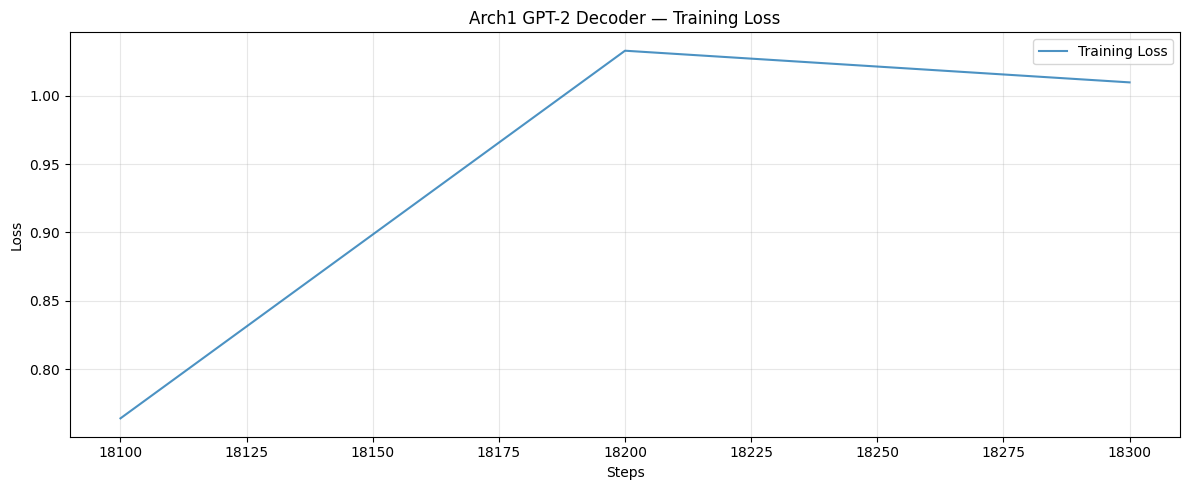

Plot saved: /kaggle/working/arch1_gpt2/training_validation_loss.png


In [15]:
plt.figure(figsize=(12, 5))
plt.plot(train_log["steps"], train_log["losses"], label="Training Loss", alpha=0.8)
# Validation loop was removed for strict token-budget stream, so only train loss is plotted
plt.xlabel("Steps")
plt.ylabel("Loss")
plt.title("Arch1 GPT-2 Decoder — Training Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()
print(f"Plot saved: {LOSS_PLOT_PATH}")


## 13. Save and Push Model

In [16]:
torch.save(model.state_dict(), os.path.join(MODEL_DIR, "model_state_dict.pt"))

model_config = {
    "architecture": "GPT2LM",
    "vocab_size": VOCAB_SIZE, "d_model": N_EMBD, "n_head": N_HEAD,
    "n_layer": N_LAYER, "d_ff": D_FF, "dropout": DROPOUT,
    "max_len": CONTEXT_LENGTH, "param_count": param_count
}
with open(os.path.join(MODEL_DIR, "config.json"), "w") as f:
    json.dump(model_config, f, indent=2)

print(f"Model saved locally: {MODEL_DIR}")

api = HfApi()
api.create_repo(HF_MODEL_REPO, token=HF_TOKEN, exist_ok=True)
api.upload_folder(folder_path=MODEL_DIR, repo_id=HF_MODEL_REPO, token=HF_TOKEN)
print(f"Pushed to HF Hub: {HF_MODEL_REPO}")

del optimizer, scheduler, scaler, train_loader
gc.collect()
torch.cuda.empty_cache()

Model saved locally: /kaggle/working/arch1_gpt2/model
Pushed to HF Hub: D-240357/legal-gpt2-decoder


## 14. Download Test Data

In [17]:
test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TEST_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)

with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

print(f"Test examples: {len(test_data)}")

test.json:   0%|          | 0.00/3.03M [00:00<?, ?B/s]

Test examples: 1000


## 15. Load Model for Generation

In [18]:
gen_tokenizer = CustomTokenizer()
gen_tokenizer.load(os.path.join(MODEL_DIR, "custom_tokenizer.json"))

with open(os.path.join(MODEL_DIR, "config.json"), "r") as f:
    saved_config = json.load(f)

gen_model = GPT2LM(
    vocab_size=saved_config["vocab_size"],
    d_model=saved_config["d_model"],
    n_head=saved_config["n_head"],
    n_layer=saved_config["n_layer"],
    d_ff=saved_config["d_ff"],
    dropout=0.0,
    max_len=saved_config["max_len"]
).to(device)

state_dict = torch.load(os.path.join(MODEL_DIR, "model_state_dict.pt"), map_location=device)
cleaned = {k.replace("_orig_mod.", ""): v for k, v in state_dict.items()}
gen_model.load_state_dict(cleaned)
del state_dict, cleaned
gen_model.eval()


print(f"Model loaded for generation.")
print(f"Parameters: {sum(p.numel() for p in gen_model.parameters()) / 1e6:.2f}M")

Model loaded for generation.
Parameters: 111.20M


## 16. Generate Predictions

In [19]:
@torch.no_grad()
def generate(prompt_text, mdl, tok, dev, target_words=128, max_tokens=384):
    input_ids = tok.encode(prompt_text)
    input_ids = input_ids[-(CONTEXT_LENGTH - max_tokens):]

    generated = list(input_ids)
    prompt_len = len(input_ids)

    for _ in range(max_tokens):
        context = generated[-(CONTEXT_LENGTH):]
        x = torch.tensor([context], dtype=torch.long, device=dev)

        with torch.amp.autocast('cuda'):
            logits = mdl(x)

        next_logits = logits[0, -1, :] / GEN_TEMPERATURE

        sorted_logits, sorted_indices = torch.sort(next_logits, descending=True)
        cum_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
        remove_mask = cum_probs - F.softmax(sorted_logits, dim=-1) >= GEN_TOP_P
        sorted_logits[remove_mask] = -float("inf")

        if GEN_TOP_K > 0:
            sorted_logits[GEN_TOP_K:] = -float("inf")

        probs = F.softmax(sorted_logits, dim=-1)
        next_token_idx = torch.multinomial(probs, 1)
        next_token = sorted_indices[next_token_idx].item()

        if next_token == EOS_ID:
            break

        generated.append(next_token)

        new_tokens = generated[prompt_len:]
        decoded = tok.decode(new_tokens)
        if len(decoded.split()) >= target_words:
            break

    new_tokens = generated[prompt_len:]
    decoded = tok.decode(new_tokens)
    words = decoded.split()[:target_words]
    return " ".join(words)


predictions = {}
items = list(test_data.items())
total = len(items)
print(f"Generating for {total} test examples...")

for idx, (example_id, record) in enumerate(items):
    pred = generate(record["text"], gen_model, gen_tokenizer, device, TARGET_WORDS, MAX_NEW_TOKENS)
    predictions[str(example_id)] = {"text": pred}

    if (idx + 1) % 10 == 0 or (idx + 1) == total:
        print(f"  {idx+1}/{total} ({100*(idx+1)/total:.1f}%)")

    if (idx + 1) % 50 == 0:
        torch.cuda.empty_cache()

print(f"Generation complete. Total predictions: {len(predictions)}")

Generating for 1000 test examples...
  10/1000 (1.0%)
  20/1000 (2.0%)
  30/1000 (3.0%)
  40/1000 (4.0%)
  50/1000 (5.0%)
  60/1000 (6.0%)
  70/1000 (7.0%)
  80/1000 (8.0%)
  90/1000 (9.0%)
  100/1000 (10.0%)
  110/1000 (11.0%)
  120/1000 (12.0%)
  130/1000 (13.0%)
  140/1000 (14.0%)
  150/1000 (15.0%)
  160/1000 (16.0%)
  170/1000 (17.0%)
  180/1000 (18.0%)
  190/1000 (19.0%)
  200/1000 (20.0%)
  210/1000 (21.0%)
  220/1000 (22.0%)
  230/1000 (23.0%)
  240/1000 (24.0%)
  250/1000 (25.0%)
  260/1000 (26.0%)
  270/1000 (27.0%)
  280/1000 (28.0%)
  290/1000 (29.0%)
  300/1000 (30.0%)
  310/1000 (31.0%)
  320/1000 (32.0%)
  330/1000 (33.0%)
  340/1000 (34.0%)
  350/1000 (35.0%)
  360/1000 (36.0%)
  370/1000 (37.0%)
  380/1000 (38.0%)
  390/1000 (39.0%)
  400/1000 (40.0%)
  410/1000 (41.0%)
  420/1000 (42.0%)
  430/1000 (43.0%)
  440/1000 (44.0%)
  450/1000 (45.0%)
  460/1000 (46.0%)
  470/1000 (47.0%)
  480/1000 (48.0%)
  490/1000 (49.0%)
  500/1000 (50.0%)
  510/1000 (51.0%)
  520/1000 (

## 17. Save Predictions

In [20]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)

print(f"Predictions saved: {PREDICTION_PATH}")

sample_keys = list(predictions.keys())[:3]
for k in sample_keys:
    words = predictions[k]["text"].split()
    print(f"Example {k} ({len(words)} words):")
    print(predictions[k]["text"][:200] + "...")

Predictions saved: /kaggle/working/arch1_gpt2/prediction.json
Example 1 (128 words):
not open for the court to exercise its jurisdiction under article 226 of the constitution to exercise its jurisdiction under article 226 of the constitution to exercise its jurisdiction under article ...
Example 2 (128 words):
on the ground that the complaint is not maintainable and against the orders of the magistrate passed in. no. of 2004, dated 04. 07. 2009, as stated in the affidavit filed herein the high court can tak...
Example 3 (128 words):
. (7) where the magistrate is of opinion that any part of the statement is not relevant to the subject - matter of the proceedings before him, the magistrate may, in any case, direct the person to be ...


## 18. Create Submission ZIP

In [21]:
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")

print(f"Submission ZIP created: {SUBMISSION_ZIP}")
print(f"ZIP size: {os.path.getsize(SUBMISSION_ZIP) / 1024:.1f} KB")

Submission ZIP created: /kaggle/working/arch1_gpt2/submission.zip
ZIP size: 156.8 KB
